# Evaluación por fuente: ¿los modelos reconocen la enfermedad o el origen de la imagen?

Las clases del dataset **no vienen de las mismas fuentes**: Silicosis y STB solo de SilicoData, COVID-19 casi todo de COVID-QU-Ex,
Neumonía de dos fuentes con poblaciones muy distintas (niños y adultos). Un modelo puede acertar mucho "porque reconoce la fuente"
(bordes, contraste, marcas, resolución) y no la patología. El F1 global no lo distingue.

**Qué se hace aquí** (solo con las predicciones guardadas del test, sin reentrenar nada):

1. **Composición clase × fuente** del test: cuánto está confundida cada clase con su fuente.
2. **Exactitud balanceada dentro de cada fuente** (promedio de recall por clase usando solo las imágenes de esa fuente). Dentro de una misma
   fuente la "firma de la fuente" no ayuda a separar clases, así que mide discriminación real. Si un modelo es bueno en el global pero malo
   dentro de las fuentes, hay sospecha de atajo.
3. **Recall de la misma clase en fuentes distintas** (Normal, Tuberculosis, COVID-19, Neumonía): una clase que se reconoce al 95 % en una fuente
   y al 60 % en otra delata dependencia de la fuente.
4. **Prueba de fuego**: las radiografías *Normales* de SilicoData. Si el modelo asocia el aspecto de SilicoData con Silicosis/STB/TB,
   las clasificará como enfermas.
5. **¿Cambia el ranking** si se promedia por fuente en vez de mezclar todo?

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

RESULTS_DIR = Path("../resultados/resultados_entrenamiento")
MANIFEST_DIR = Path("../dataset_final_224/manifiestos")
OUTPUT_DIR = Path("../resultados/analisis_por_fuente")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RNG_SEED, N_BOOT, MIN_N = 42, 1000, 30

RUNS = {  # (variante, corrida) -> carpeta
    ("6clases_con_exclusion", "A"): RESULTS_DIR / "6_clases_con_exclusion",
    ("6clases_con_exclusion", "B"): RESULTS_DIR / "6_clases_con_exclusion_224",
    ("5clases_con_exclusion", "A"): RESULTS_DIR / "5_clases_con_exclusion",
    ("6clases_sin_excluir", "A"): RESULTS_DIR / "6_clases_sin_exclusion",
    ("5clases_sin_excluir", "A"): RESULTS_DIR / "5_clases_sin_exclusion",
}
NICE = {"vgg16_bn": "VGG16", "mobilenetv3_small_100": "MobileNetV3", "resnet50": "ResNet50", "efficientnet_b0": "EfficientNetB0",
        "swin_tiny_patch4_window7_224": "Swin-Tiny", "vit_base_patch16_224": "ViT-Base", "deit_base_patch16_224": "DeiT-Base",
        "coatnet_0_rw_224": "CoAtNet", "maxvit_tiny_tf_224": "MaxViT", "custom_cnn_transformer": "Custom"}
SRC_NICE = {"COVID-QU-Ex": "COVID-QU-Ex", "Chest_x_ray": "Chest X-ray", "RSNA_Pneumonia": "RSNA", "Shenzhen_Montgomery": "Shenzhen/Montg.",
            "SilicoData": "SilicoData", "TBX11K-simplified": "TBX11K", "VinDr_CXR": "VinDr-CXR"}
SRC_ORDER = ["COVID-QU-Ex", "Chest_x_ray", "RSNA_Pneumonia", "SilicoData", "TBX11K-simplified", "Shenzhen_Montgomery", "VinDr_CXR"]
CLASSES = {"6": ["COVID-19", "Normal", "Pneumonia", "Silicosis", "STB", "Tuberculosis"],
           "5": ["COVID-19", "Normal", "Pneumonia", "Silicosis", "Tuberculosis"]}
CLS_COLOR = {"COVID-19": "#C8503C", "Normal": "#3DA66B", "Pneumonia": "#E8A33A", "Tuberculosis": "#3E63AE", "Silicosis": "#7B5EA7", "STB": "#2BA3B5"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def save_fig(name):
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=600, bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")

def load_run(folder):
    out = {}
    for f in sorted(folder.rglob("*__*.json")):
        if f.name.endswith("_metricas_por_clase.json"):
            continue
        d = json.load(open(f, encoding="utf-8"))
        if "history" not in d:
            continue
        npz = np.load(f.with_name(f.stem + "_predicciones.npz"))
        out[NICE.get(d["model_name"], d["model_name"])] = {"y_true": npz["y_true"], "y_pred": npz["y_pred"]}
    return out

# test de cada variante (mismo orden que las predicciones) con su fuente
TEST, RES = {}, {}
for variant in {k[0] for k in RUNS}:
    classes = CLASSES["5" if "5clases" in variant else "6"]
    t = pd.read_csv(MANIFEST_DIR / f"manifiesto_{variant}.csv")
    t = t[t.split == "test"].reset_index(drop=True)
    t["y"] = t.target_class.map({c: i for i, c in enumerate(classes)})
    TEST[variant] = t
for (variant, run), folder in RUNS.items():
    for m, r in load_run(folder).items():
        assert np.array_equal(r["y_true"], TEST[variant].y.to_numpy()), (variant, run, m)      # mismo orden e imágenes
        RES[(variant, run, m)] = r
print(f"{len(RES)} resultados cargados; el orden del test coincide con el manifiesto en todos.")

50 resultados cargados; el orden del test coincide con el manifiesto en todos.


## 1. Cuánto está confundida cada clase con su fuente

Para cada clase: qué fracción de sus imágenes de test viene de cada fuente. Una clase con el 100 % en una sola fuente **no se puede separar**
de esa fuente (variante `5clases_con_exclusion`, la que sirve la app).

source_dataset  COVID-QU-Ex  Chest_x_ray  RSNA_Pneumonia  SilicoData  TBX11K-simplified  Shenzhen_Montgomery  VinDr_CXR
target_class                                                                                                           
COVID-19                809           86               0           0                  0                    0          0
Normal                  197          191             204          73                190                   46          0
Pneumonia                 0          450             448           0                  0                    0          0
Silicosis                 0            0               0         162                  0                    0          0
Tuberculosis              0          102               0         113                120                   58         97

source_dataset  COVID-QU-Ex  Chest_x_ray  RSNA_Pneumonia  SilicoData  TBX11K-simplified  Shenzhen_Montgomery  VinDr_CXR
target_class                           

/tmp/ipykernel_116828/3197075828.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  comp_pct = comp.div(comp.sum(1), axis=0)
/tmp/ipykernel_116828/3197075828.py:7: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  dom = comp_pct.max(1)


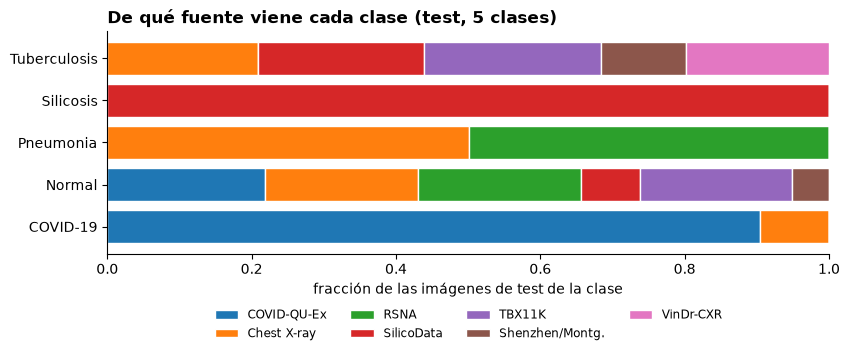

In [2]:
t5 = TEST["5clases_con_exclusion"]
comp = pd.crosstab(t5.target_class, t5.source_dataset).reindex(columns=SRC_ORDER, fill_value=0)
comp_pct = comp.div(comp.sum(1), axis=0)
comp.to_csv(OUTPUT_DIR / "composicion_clase_fuente_test_5clases.csv")
print(comp.to_string()); print()
print((comp_pct * 100).round(0).astype(int).to_string())
dom = comp_pct.max(1)
print("\nFuente dominante por clase:", {c: f"{SRC_NICE[comp_pct.loc[c].idxmax()]} ({dom[c]:.0%})" for c in comp.index})

fig, ax = plt.subplots(figsize=(8.6, 3.8))
left = np.zeros(len(comp))
for s in SRC_ORDER:
    ax.barh(comp.index, comp_pct[s], left=left, label=SRC_NICE[s], edgecolor="white", lw=1)
    left += comp_pct[s].to_numpy()
ax.set_xlabel("fracción de las imágenes de test de la clase"); ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.2), fontsize=8.5)
ax.set_title("De qué fuente viene cada clase (test, 5 clases)", loc="left", fontweight="bold")
plt.tight_layout(); save_fig("fig_composicion_clase_fuente"); plt.show()

## 2. Exactitud balanceada dentro de cada fuente

Para cada resultado y cada fuente se usan **solo** las imágenes de esa fuente y se promedia el recall de las clases que hay en ella
(exactitud balanceada). Intervalo bootstrap del 95 % (1 000 remuestreos). Las fuentes de una sola clase (VinDr-CXR: solo Tuberculosis)
miden sensibilidad, no discriminación. Con menos de 30 imágenes el valor es solo orientativo.

In [3]:
rng = np.random.default_rng(RNG_SEED)

def bal_acc(y, p):
    cl = np.unique(y)
    return float(np.mean([(p[y == c] == c).mean() for c in cl]))

def boot_ci(y, p, n=N_BOOT):
    v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        v.append(bal_acc(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

rows = []
for (variant, run, m), r in RES.items():
    t = TEST[variant]; y, p = r["y_true"], r["y_pred"]
    row_g = {"variante": variant, "corrida": run, "modelo": m, "fuente": "GLOBAL", "n": len(y), "n_clases": len(np.unique(y)),
             "exactitud": float((p == y).mean()), "bal_acc": bal_acc(y, p)}
    rows.append(row_g)
    for s in SRC_ORDER:
        idx = (t.source_dataset == s).to_numpy()
        if idx.sum() == 0:
            continue
        ys, ps = y[idx], p[idx]
        lo, hi = boot_ci(ys, ps)
        rows.append({"variante": variant, "corrida": run, "modelo": m, "fuente": s, "n": int(idx.sum()), "n_clases": len(np.unique(ys)),
                     "exactitud": float((ps == ys).mean()), "bal_acc": bal_acc(ys, ps), "ic_inf": lo, "ic_sup": hi})
PF = pd.DataFrame(rows)
PF.to_csv(OUTPUT_DIR / "tabla_por_fuente.csv", index=False)
print(PF[PF.variante == "5clases_con_exclusion"].pivot(index="modelo", columns="fuente", values="bal_acc")[["GLOBAL"] + SRC_ORDER].round(3).to_string())

fuente          GLOBAL  COVID-QU-Ex  Chest_x_ray  RSNA_Pneumonia  SilicoData  TBX11K-simplified  Shenzhen_Montgomery  VinDr_CXR
modelo                                                                                                                         
CoAtNet          0.875        0.896        0.909           0.853       0.582              0.931                0.834      0.918
Custom           0.780        0.799        0.782           0.780       0.370              0.792                0.680      0.701
DeiT-Base        0.880        0.915        0.903           0.870       0.598              0.933                0.736      0.897
EfficientNetB0   0.819        0.807        0.829           0.782       0.564              0.883                0.777      0.907
MaxViT           0.852        0.842        0.872           0.841       0.524              0.942                0.768      0.938
MobileNetV3      0.847        0.824        0.851           0.800       0.458              0.939         

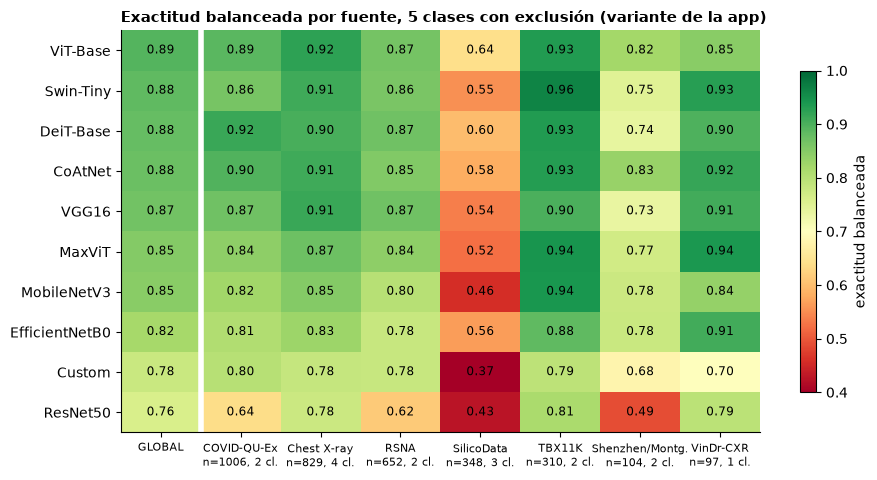

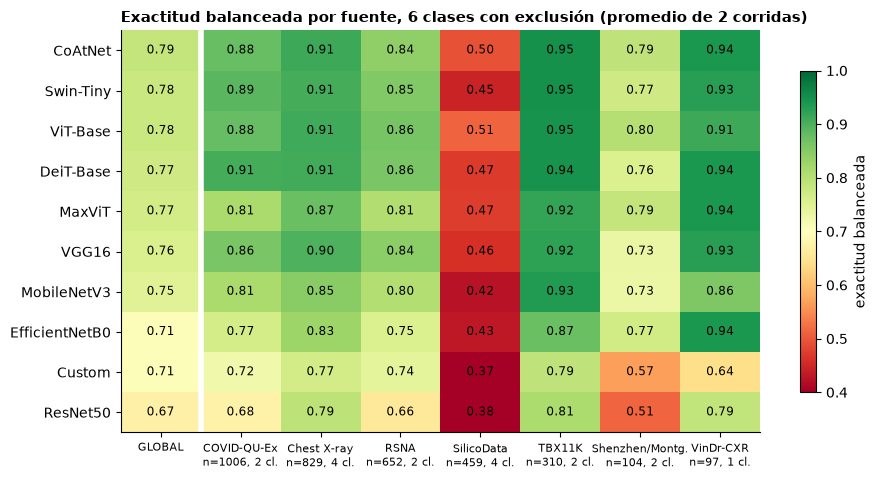

In [4]:
def heat(variant, corridas, title, name):
    d = PF[(PF.variante == variant) & PF.corrida.isin(corridas)]
    M = d.groupby(["modelo", "fuente"]).bal_acc.mean().unstack()[["GLOBAL"] + SRC_ORDER]
    M = M.loc[M["GLOBAL"].sort_values(ascending=False).index]
    nsrc = d[d.fuente != "GLOBAL"].groupby("fuente").n.first().reindex(SRC_ORDER)
    ncl = d[d.fuente != "GLOBAL"].groupby("fuente").n_clases.first().reindex(SRC_ORDER)
    fig, ax = plt.subplots(figsize=(9.4, 4.9))
    im = ax.imshow(M.values, cmap="RdYlGn", vmin=.4, vmax=1.0, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color="black")
    labels = ["GLOBAL"] + [f"{SRC_NICE[s]}\nn={nsrc[s]}, {ncl[s]} cl." for s in SRC_ORDER]
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(labels, fontsize=8); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    ax.axvline(.5, color="white", lw=4); ax.set_title(title, loc="left", fontweight="bold", fontsize=10.5)
    plt.colorbar(im, shrink=.8, label="exactitud balanceada"); plt.tight_layout(); save_fig(name); plt.show()
    return M

M5 = heat("5clases_con_exclusion", ["A"], "Exactitud balanceada por fuente, 5 clases con exclusión (variante de la app)", "fig_por_fuente_5clases")
M6 = heat("6clases_con_exclusion", ["A", "B"], "Exactitud balanceada por fuente, 6 clases con exclusión (promedio de 2 corridas)", "fig_por_fuente_6clases")

## 3. ¿La misma clase se reconoce igual en fuentes distintas?

Solo las clases que aparecen en **más de una fuente** (Normal, Tuberculosis, COVID-19, Neumonía). Cada celda es el recall de esa clase
usando solo imágenes de esa fuente. Si un modelo reconoce Normal al 97 % en una fuente y al 70 % en otra, esa diferencia no puede venir de
la patología (todas son "normales").

In [5]:
rows = []
for (variant, run, m), r in RES.items():
    t = TEST[variant]; y, p = r["y_true"], r["y_pred"]; classes = CLASSES["5" if "5clases" in variant else "6"]
    for c_i, c in enumerate(classes):
        for s in SRC_ORDER:
            idx = ((t.source_dataset == s) & (t.y == c_i)).to_numpy()
            if idx.sum() == 0:
                continue
            k = int((p[idx] == c_i).sum()); n = int(idx.sum()); z = 1.96
            ph = k / n; den = 1 + z * z / n; ctr = (ph + z * z / (2 * n)) / den; hw = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
            rows.append({"variante": variant, "corrida": run, "modelo": m, "clase": c, "fuente": s, "n": n, "recall": ph, "ic_inf": ctr - hw, "ic_sup": ctr + hw})
CS = pd.DataFrame(rows)
CS.to_csv(OUTPUT_DIR / "tabla_clase_fuente.csv", index=False)
multi = CS[CS.variante == "5clases_con_exclusion"].groupby("clase").fuente.nunique()
multi = multi[multi > 1].index.tolist()
print("Clases presentes en más de una fuente:", multi)
spread = []
for c in multi:
    d = CS[(CS.variante == "5clases_con_exclusion") & (CS.clase == c) & (CS.n >= MIN_N)]
    g = d.groupby("modelo").recall.agg(["min", "max"])
    g["rango"] = g["max"] - g["min"]; g["clase"] = c
    spread.append(g.reset_index())
spread = pd.concat(spread)
print("\nRango de recall de la MISMA clase entre fuentes (n>=30), 5 clases:")
print(spread.pivot(index="modelo", columns="clase", values="rango").round(2).to_string())

Clases presentes en más de una fuente: ['COVID-19', 'Normal', 'Pneumonia', 'Tuberculosis']

Rango de recall de la MISMA clase entre fuentes (n>=30), 5 clases:
clase           COVID-19  Normal  Pneumonia  Tuberculosis
modelo                                                   
CoAtNet             0.15    0.64       0.12          0.43
Custom              0.16    0.87       0.13          0.66
DeiT-Base           0.09    0.62       0.05          0.39
EfficientNetB0      0.15    0.55       0.05          0.57
MaxViT              0.14    0.86       0.07          0.37
MobileNetV3         0.14    0.88       0.12          0.59
ResNet50            0.18    0.70       0.23          0.57
Swin-Tiny           0.11    0.73       0.06          0.48
VGG16               0.15    0.62       0.10          0.60
ViT-Base            0.10    0.58       0.07          0.39


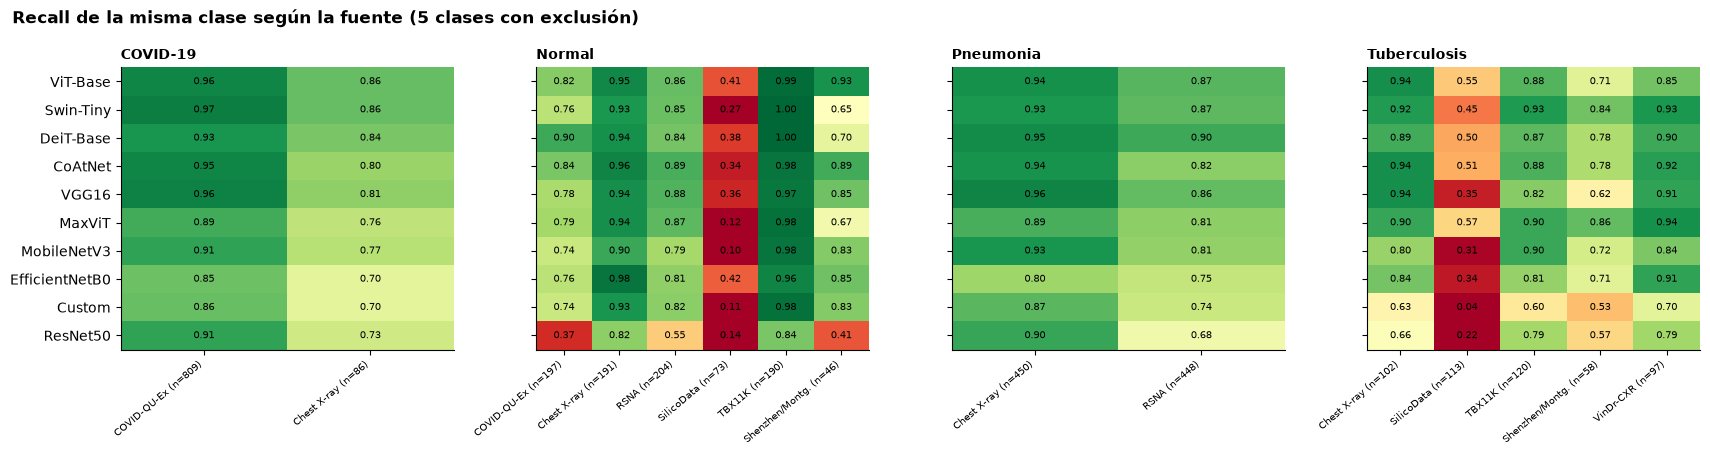

In [6]:
fig, axs = plt.subplots(1, len(multi), figsize=(4.3 * len(multi), 4.6), sharey=True)
for ax, c in zip(np.atleast_1d(axs), multi):
    d = CS[(CS.variante == "5clases_con_exclusion") & (CS.clase == c)]
    Mc = d.pivot(index="modelo", columns="fuente", values="recall").reindex(columns=[s for s in SRC_ORDER if s in d.fuente.unique()])
    Mc = Mc.loc[M5.index]
    nn = d.groupby("fuente").n.first().reindex(Mc.columns)
    im = ax.imshow(Mc.values, cmap="RdYlGn", vmin=.3, vmax=1.0, aspect="auto")
    for i in range(Mc.shape[0]):
        for j in range(Mc.shape[1]):
            ax.text(j, i, f"{Mc.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
    ax.set_xticks(range(Mc.shape[1])); ax.set_xticklabels([f"{SRC_NICE[s]} (n={nn[s]})" for s in Mc.columns], fontsize=7, rotation=40, ha="right")
    ax.set_title(c, loc="left", fontweight="bold", fontsize=10)
np.atleast_1d(axs)[0].set_yticks(range(len(M5.index))); np.atleast_1d(axs)[0].set_yticklabels(M5.index)
fig.suptitle("Recall de la misma clase según la fuente (5 clases con exclusión)", x=.01, ha="left", fontweight="bold")
plt.tight_layout(); save_fig("fig_recall_clase_por_fuente"); plt.show()

## 4. Prueba de fuego: las radiografías *Normales* de SilicoData

SilicoData aporta Silicosis, STB y Tuberculosis (enfermedad), pero también **Normales** del mismo equipo y protocolo. Si un modelo asocia
"aspecto de SilicoData" con enfermedad, esas Normales se clasificarán como enfermas. Se compara con las Normales de las demás fuentes.

                n_sil  recall_Normal_SilicoData  recall_Normal_otras  diferencia
modelo                                                                          
MobileNetV3        73                     0.096                0.849      -0.753
Custom             73                     0.110                0.865      -0.755
MaxViT             73                     0.123                0.883      -0.760
ResNet50           73                     0.137                0.627      -0.490
Swin-Tiny          73                     0.274                0.871      -0.597
CoAtNet            73                     0.342                0.913      -0.571
VGG16              73                     0.356                0.890      -0.534
DeiT-Base          73                     0.384                0.906      -0.522
ViT-Base           73                     0.411                0.906      -0.495
EfficientNetB0     73                     0.425                0.874      -0.450


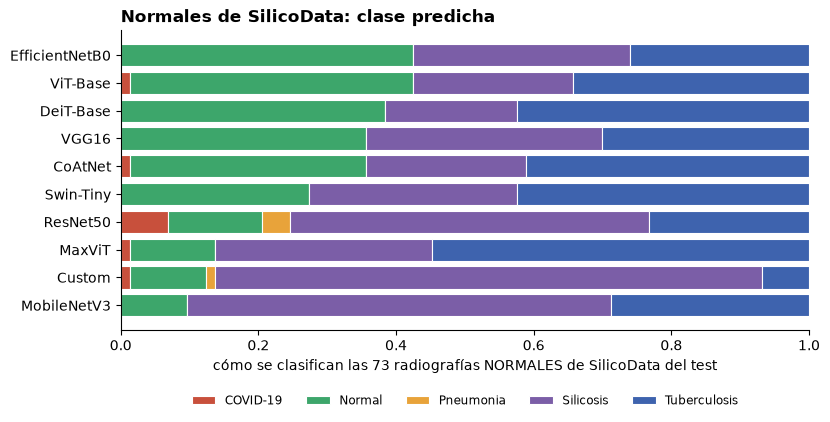

In [7]:
rows = []
for (variant, run, m), r in RES.items():
    if variant != "5clases_con_exclusion":
        continue
    t = TEST[variant]; y, p = r["y_true"], r["y_pred"]; classes = CLASSES["5"]; ni = classes.index("Normal")
    sil = ((t.source_dataset == "SilicoData") & (t.y == ni)).to_numpy(); oth = ((t.source_dataset != "SilicoData") & (t.y == ni)).to_numpy()
    row = {"modelo": m, "n_sil": int(sil.sum()), "recall_Normal_SilicoData": float((p[sil] == ni).mean()), "recall_Normal_otras": float((p[oth] == ni).mean())}
    for c_i, c in enumerate(classes):
        row[f"sil_pred_{c}"] = float((p[sil] == c_i).mean())
    rows.append(row)
NS = pd.DataFrame(rows).set_index("modelo").sort_values("recall_Normal_SilicoData")
NS["diferencia"] = NS.recall_Normal_SilicoData - NS.recall_Normal_otras
NS.to_csv(OUTPUT_DIR / "normales_silicodata.csv")
print(NS[["n_sil", "recall_Normal_SilicoData", "recall_Normal_otras", "diferencia"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(8.4, 4.4))
left = np.zeros(len(NS))
for c in CLASSES["5"]:
    ax.barh(NS.index, NS[f"sil_pred_{c}"], left=left, color=CLS_COLOR[c], label=c, edgecolor="white", lw=.8)
    left += NS[f"sil_pred_{c}"].to_numpy()
ax.set_xlabel(f"cómo se clasifican las {int(NS.n_sil.iloc[0])} radiografías NORMALES de SilicoData del test"); ax.set_xlim(0, 1)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(.5, -.18), fontsize=8.5)
ax.set_title("Normales de SilicoData: clase predicha", loc="left", fontweight="bold")
plt.tight_layout(); save_fig("fig_normales_silicodata"); plt.show()

## 5. ¿Cambia el ranking si se promedia por fuente?

El F1 global está dominado por las fuentes grandes. Alternativa: promediar la exactitud balanceada **de cada fuente con igual peso**
(solo fuentes con ≥ 2 clases y ≥ 30 imágenes: así se mide discriminación dentro de la fuente).

In [8]:
d = PF[(PF.fuente != "GLOBAL") & (PF.n_clases >= 2) & (PF.n >= MIN_N)]
rows = []
for variant in ["5clases_con_exclusion", "6clases_con_exclusion", "6clases_sin_excluir", "5clases_sin_excluir"]:
    corr = ["B"] if variant == "6clases_con_exclusion" else ["A"]  # la corrida B es la oficial de esta variante
    dv = d[(d.variante == variant) & d.corrida.isin(corr)]
    g = dv.groupby("modelo").agg(media_fuentes=("bal_acc", "mean"), peor_fuente=("bal_acc", "min"))
    glob = PF[(PF.variante == variant) & (PF.fuente == "GLOBAL") & PF.corrida.isin(corr)].groupby("modelo").bal_acc.mean().rename("global")
    g = g.join(glob); g["variante"] = variant
    rho_mean, _ = spearmanr(g["global"], g.media_fuentes); rho_min, _ = spearmanr(g["global"], g.peor_fuente)
    g["rho_global_vs_media"] = rho_mean; g["rho_global_vs_peor"] = rho_min
    rows.append(g.reset_index())
RK = pd.concat(rows); RK.to_csv(OUTPUT_DIR / "ranking_por_fuente.csv", index=False)
for v, g in RK.groupby("variante"):
    print(f"{v}: Spearman global vs media por fuente {g.rho_global_vs_media.iloc[0]:.2f} | global vs peor fuente {g.rho_global_vs_peor.iloc[0]:.2f}")
print()
g5 = RK[RK.variante == "5clases_con_exclusion"].set_index("modelo").sort_values("global", ascending=False)
print(g5[["global", "media_fuentes", "peor_fuente"]].round(3).to_string())

5clases_con_exclusion: Spearman global vs media por fuente 0.95 | global vs peor fuente 0.81
5clases_sin_excluir: Spearman global vs media por fuente 0.79 | global vs peor fuente 0.87
6clases_con_exclusion: Spearman global vs media por fuente 0.84 | global vs peor fuente 0.82
6clases_sin_excluir: Spearman global vs media por fuente 0.81 | global vs peor fuente 0.83

                global  media_fuentes  peor_fuente
modelo                                            
ViT-Base         0.894          0.845        0.641
Swin-Tiny        0.884          0.816        0.555
DeiT-Base        0.880          0.826        0.598
CoAtNet          0.875          0.834        0.582
VGG16            0.868          0.804        0.536
MaxViT           0.852          0.798        0.524
MobileNetV3      0.847          0.775        0.458
EfficientNetB0   0.819          0.774        0.564
Custom           0.780          0.701        0.370
ResNet50         0.760          0.627        0.428


## 6. Resumen

In [9]:
g5 = RK[RK.variante == "5clases_con_exclusion"].set_index("modelo")
fuente_peor = PF[(PF.variante == "5clases_con_exclusion") & (PF.fuente != "GLOBAL") & (PF.n_clases >= 2) & (PF.n >= MIN_N)].groupby("fuente").bal_acc.mean().sort_values()
top4 = ["ViT-Base", "CoAtNet", "Swin-Tiny", "DeiT-Base"]
ns_top = NS.loc[top4]
print(f"CONFUSIÓN CLASE-FUENTE (test, 5 clases): " + "; ".join(f"{c}: {dom[c]:.0%} de {SRC_NICE[comp_pct.loc[c].idxmax()]}" for c in comp.index) + ".")
print()
print("DENTRO DE CADA FUENTE (exactitud balanceada media de los 10 modelos, 5 clases): " + ", ".join(f"{SRC_NICE[s]} {v:.2f}" for s, v in fuente_peor.items()) + ".")
print(f"GLOBAL medio: {g5['global'].mean():.2f}; media por fuente: {g5.media_fuentes.mean():.2f}; peor fuente por modelo: {g5.peor_fuente.mean():.2f}.")
print()
print(f"NORMALES DE SILICODATA (n={int(NS.n_sil.iloc[0])}): recall medio {NS.recall_Normal_SilicoData.mean():.2f} frente a {NS.recall_Normal_otras.mean():.2f} en las Normales de otras fuentes; "
      f"para los 4 primeros {ns_top.recall_Normal_SilicoData.mean():.2f} frente a {ns_top.recall_Normal_otras.mean():.2f}.")
print()
print("RANKING: Spearman entre el orden global y el orden por media de fuentes: " + ", ".join(f"{v.split('clases')[0]}c {'excl.' if 'con' in v else 'sin'}={g.rho_global_vs_media.iloc[0]:.2f}" for v, g in RK.groupby("variante")) + ".")

CONFUSIÓN CLASE-FUENTE (test, 5 clases): COVID-19: 90% de COVID-QU-Ex; Normal: 23% de RSNA; Pneumonia: 50% de Chest X-ray; Silicosis: 100% de SilicoData; Tuberculosis: 24% de TBX11K.

DENTRO DE CADA FUENTE (exactitud balanceada media de los 10 modelos, 5 clases): SilicoData 0.53, Shenzhen/Montg. 0.74, RSNA 0.81, COVID-QU-Ex 0.83, Chest X-ray 0.87, TBX11K 0.90.
GLOBAL medio: 0.85; media por fuente: 0.78; peor fuente por modelo: 0.53.

NORMALES DE SILICODATA (n=73): recall medio 0.27 frente a 0.86 en las Normales de otras fuentes; para los 4 primeros 0.35 frente a 0.90.

RANKING: Spearman entre el orden global y el orden por media de fuentes: 5c excl.=0.95, 5c sin=0.79, 6c excl.=0.84, 6c sin=0.81.
